In [41]:
import pandas as pd
import numpy as np
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, log_loss, 
                             classification_report, average_precision_score, precision_recall_curve)
from catboost import CatBoostClassifier

import optuna
from preprocessing import import_data
from scoring import score

import warnings
warnings.filterwarnings("ignore")

In [42]:
pd.set_option('display.max_columns', None)

# Preprocessing Data

In [43]:
Xt,yt,Xv,yv = import_data()

Importing train/validation data...
Finished the import.


In [44]:
def group_medications(df):
    groups = {
        "biguanide": ["metformin"],
        "meglitinide": ["repaglinide", "nateglinide"],
        "sulfonylurea_gen1": ["chlorpropamide", "acetohexamide", "tolbutamide", "tolazamide"],
        "sulfonylurea_gen2": ["glimepiride", "glipizide", "glyburide"],
        "thiazolidinedione": ["pioglitazone", "rosiglitazone", "troglitazone"],
        "alpha_glucosidase_inhibitor": ["acarbose", "miglitol"],
        "biguanide_sulfonylurea_gen2": ["glyburide-metformin", "glipizide-metformin"],
        "biguanide_thiazolidinedione": ["metformin-rosiglitazone", "metformin-pioglitazone"],
        "sulfonylurea_gen2_thiazolidinedione": ["glimepiride-pioglitazone"],
    }

    result = df.copy()
    priority = ["Up", "Down", "Steady"]

    for group, medications in groups.items():
        columns = df.columns.intersection(medications)
        if len(columns):
            values = df[columns]
            result = result.drop(columns=columns)
            result[group] = np.select([values.eq(status).any(axis=1) for status in priority], priority, default="No")

    return result

# Xt=group_medications(Xt)
# Xv=group_medications(Xv)

In [45]:
# Removing outliers

# Remove entries 4 standard deviations out
def remove_upper_outliers(df, columns, n_std=5):
    x = df[columns]
    upper = x.mean() + n_std * x.std(ddof=0)
    remove = x.gt(upper).any(axis=1)

    print(f"Removed {remove.sum():,} of {len(df):,} rows")
    return df.loc[~remove].copy()

numerical_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
]

In [46]:
# train_filtered = remove_upper_outliers(Xt, numerical_features)
# Xt = train_filtered.drop(columns="target")
# yt = train_filtered["target"]

In [47]:
def group_diagnoses(df):
    import pandas as pd

    ranges = {"Circulatory": (390, 459), "Respiratory": (460, 519),
        "Digestive": (520, 579), "Genitourinary": (580, 629),
        "Musculoskeletal": (710, 739), "Neoplasms": (140, 239), "Injury": (800, 999)}
    
    symptoms = {785: "Circulatory", 786: "Respiratory", 787: "Digestive", 788: "Genitourinary"}

    def categorize(value):
        if pd.isna(value):
            return "Missing"

        code = str(value).strip().upper()
        if code in {"", "?", "NAN", "NONE", "MISSING"}:
            return "Missing"

        # Supplementary V/E codes belong to the broad Other category.
        if code.startswith(("V", "E")):
            return "Other"

        try:
            number = float(code)
            if not 1 <= number < 1000:
                return "Other"
            code = int(number)  # 250.13 -> 250, 459.9 -> 459
        except ValueError:
            return "Other"

        if code == 250:
            return "Diabetes"
        if code in symptoms:
            return symptoms[code]
        for group, (lower, upper) in ranges.items():
            if lower <= code <= upper:
                return group
        return "Other"

    result = df.copy()
    for column in ("diag_1", "diag_2", "diag_3", "diaga_3"):
        if column in result.columns:
            result[column] = result[column].map(categorize)

    return result

In [48]:
# Xt = group_diagnoses(Xt)
# Xv = group_diagnoses(Xv)

In [49]:
# prepare for catboost
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]


# careful! catboost demands categorical columns to have string entry
Xt_cb, Xv_cb = Xt.copy(), Xv.copy()
for c in cat_cols:
    for df in (Xt_cb, Xv_cb):
        df[c] = df[c].astype(object).where(df[c].notna(), "missing").astype(str)

In [50]:
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42),)

# Include a configuration as the first trial.
study.enqueue_trial({'bootstrap_type': 'No', 'iterations': 7300, 
                    'learning_rate': 0.0022844556850020537, 'depth': 9, 
                    'l2_leaf_reg': 11.044350847124697, 
                    'scale_pos_weight': 1.1916467090032163})

best_f1 = -1.0

for _ in range(10):
    trial = study.ask()

    bootstrap = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli", "Poisson", "No"])
    bagging = {"bootstrap_type": bootstrap}

    if bootstrap == "Bayesian":
        bagging["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.1, 1.0)
    elif bootstrap in ["Bernoulli", "Poisson"]:
        bagging["subsample"] = trial.suggest_float("subsample", 0.1, 1.0)

    candidate = CatBoostClassifier(
        iterations=trial.suggest_int("iterations", 500, 7_500, step=25),
        learning_rate=trial.suggest_float("learning_rate", 0.001, 1.000, log=True),
        depth=trial.suggest_int("depth", 1, 12),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 0.01, 100.0, log=True),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 0.01, 50.00, log=True),
        **bagging,
        loss_function="Logloss",
        task_type="GPU",
        devices="0",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )

    candidate.fit(Xt_cb, yt, cat_features=cat_cols)
    trial_proba = candidate.predict_proba(Xv_cb)[:, 1]

    # chooses a new optimal threshold
    p, r, thr = precision_recall_curve(yv, trial_proba)
    f1s = (
        2 * p[:-1] * r[:-1]
        / np.maximum(p[:-1] + r[:-1], 1e-15)
    )

    best_index = int(np.argmax(f1s))
    trial_f1 = float(f1s[best_index])
    trial_threshold = float(thr[best_index])

    trial.set_user_attr("threshold", trial_threshold)
    study.tell(trial, trial_f1)

    # keep the winning model for later use
    if trial_f1 > best_f1:
        best_f1 = trial_f1
        model = candidate
        proba = trial_proba
        threshold = trial_threshold

    print(f"Trial {trial.number:02d} | F1={trial_f1:.4f} | threshold={trial_threshold:.4f} | best={best_f1:.4f}")

y_pred = (proba >= threshold).astype(int)

print("\nBest parameters:", study.best_params)
print(f"Best threshold: {threshold:.4f}")
print(f"F1 @0.5: {f1_score(yv, proba >= 0.5):.4f}")
print(f"Threshold-optimized F1: {best_f1:.4f}")
print("\nConfusion matrix:\n", confusion_matrix(yv, y_pred))
print(classification_report(yv, y_pred, digits=4, zero_division=0))

[I 2026-10-27 21:21:45,689] A new study created in memory with name: no-name-a69795eb-0810-4da5-a27c-dfae30c44a02


Trial 00 | F1=0.2968 | threshold=0.1721 | best=0.2968
Trial 01 | F1=0.2913 | threshold=0.4083 | best=0.2968
Trial 02 | F1=0.2879 | threshold=0.0175 | best=0.2968
Trial 03 | F1=0.2853 | threshold=0.0023 | best=0.2968
Trial 04 | F1=0.2472 | threshold=0.2474 | best=0.2968
Trial 05 | F1=0.2933 | threshold=0.1471 | best=0.2968
Trial 06 | F1=0.2822 | threshold=0.0024 | best=0.2968
Trial 07 | F1=0.2933 | threshold=0.5841 | best=0.2968
Trial 08 | F1=0.2938 | threshold=0.0030 | best=0.2968
Trial 09 | F1=0.2502 | threshold=0.2300 | best=0.2968

Best parameters: {'bootstrap_type': 'No', 'iterations': 7300, 'learning_rate': 0.0022844556850020537, 'depth': 9, 'l2_leaf_reg': 11.044350847124697, 'scale_pos_weight': 1.1916467090032163}
Best threshold: 0.1721
F1 @0.5: 0.0384
Threshold-optimized F1: 0.2968

Confusion matrix:
 [[11910  2556]
 [ 1055   762]]
              precision    recall  f1-score   support

           0     0.9186    0.8233    0.8684     14466
           1     0.2297    0.4194    0.2

In [51]:
print(study.best_params)


# {'bootstrap_type': 'No', 'iterations': 7300, 
# 'learning_rate': 0.0022844556850020537, 'depth': 9, 
# 'l2_leaf_reg': 11.044350847124697, 
# 'scale_pos_weight': 1.1916467090032163}
print(threshold)

#  0.16971838700170908

{'bootstrap_type': 'No', 'iterations': 7300, 'learning_rate': 0.0022844556850020537, 'depth': 9, 'l2_leaf_reg': 11.044350847124697, 'scale_pos_weight': 1.1916467090032163}
0.17210654294260833


In [52]:
best_parameters = study.best_params
print(best_parameters)
best_threshold = threshold
print(threshold)

cbc = CatBoostClassifier(**best_parameters,
        verbose=250,
        loss_function="Logloss",
        task_type="GPU",
        devices="0",
        random_seed=42,
        allow_writing_files=False)
cbc.fit(Xt_cb,yt, cat_features=cat_cols)

{'bootstrap_type': 'No', 'iterations': 7300, 'learning_rate': 0.0022844556850020537, 'depth': 9, 'l2_leaf_reg': 11.044350847124697, 'scale_pos_weight': 1.1916467090032163}
0.17210654294260833
0:	learn: 0.6913777	total: 73.1ms	remaining: 8m 53s
250:	learn: 0.4531034	total: 17.3s	remaining: 8m 5s
500:	learn: 0.3894855	total: 34.4s	remaining: 7m 46s
750:	learn: 0.3695023	total: 50.8s	remaining: 7m 22s
1000:	learn: 0.3614950	total: 1m 7s	remaining: 7m 2s
1250:	learn: 0.3574396	total: 1m 23s	remaining: 6m 43s
1500:	learn: 0.3546916	total: 1m 39s	remaining: 6m 25s
1750:	learn: 0.3526047	total: 1m 56s	remaining: 6m 8s
2000:	learn: 0.3508122	total: 2m 12s	remaining: 5m 51s
2250:	learn: 0.3494611	total: 2m 28s	remaining: 5m 34s
2500:	learn: 0.3484051	total: 2m 45s	remaining: 5m 17s
2750:	learn: 0.3475246	total: 3m 2s	remaining: 5m 1s
3000:	learn: 0.3464959	total: 3m 18s	remaining: 4m 44s
3250:	learn: 0.3453930	total: 3m 35s	remaining: 4m 28s
3500:	learn: 0.3443016	total: 3m 52s	remaining: 4m 12

CatBoostClassifier(allow_writing_files=False, bootstrap_type='No', depth=9, devices='0', iterations=7300, l2_leaf_reg=11.044350847124697, learning_rate=0.0022844556850020537, loss_function='Logloss', random_seed=42, scale_pos_weight=1.1916467090032163, task_type='GPU', verbose=250)

In [53]:
proba = cbc.predict_proba(Xv_cb)[:, 1]

score(yv, y_pred=None, proba=proba, threshold=best_threshold)

y_pred = (proba >= best_threshold).astype(int)

print("ROC-AUC:", round(roc_auc_score(yv, proba), 4))
print("PR-AUC: ", round(average_precision_score(yv, proba), 4))
print(f"Accuracy: {accuracy_score(yv, y_pred):.3f}")
print("\nConfusion matrix:\n", confusion_matrix(yv, y_pred))
print(f"\n\n{classification_report(yv, y_pred)}")
print(f"\nF1 @{best_threshold}: {round(f1_score(yv,y_pred),4)}")

# Best-threshold F1
p, r, thr = precision_recall_curve(yv, proba)
f1s = 2 * p * r / (p + r + 1e-12)
best = f1s[:-1].argmax()
print(f"\nBest-threshold F1: {f1s[best]:.4f} at threshold {thr[best]:.4f}")

Accuracy: 0.778
Confusion matrix:
 [[11909  2557]
 [ 1057   760]]
              precision    recall  f1-score   support

           0       0.92      0.82      0.87     14466
           1       0.23      0.42      0.30      1817

    accuracy                           0.78     16283
   macro avg       0.57      0.62      0.58     16283
weighted avg       0.84      0.78      0.80     16283

F1 @0.5: 0.296
ROC-AUC: 0.6882
PR-AUC:  0.2486
Best-threshold F1: 0.29750 at threshold 0.16589.
ROC-AUC: 0.6882
PR-AUC:  0.2486
Accuracy: 0.778

Confusion matrix:
 [[11909  2557]
 [ 1057   760]]


              precision    recall  f1-score   support

           0       0.92      0.82      0.87     14466
           1       0.23      0.42      0.30      1817

    accuracy                           0.78     16283
   macro avg       0.57      0.62      0.58     16283
weighted avg       0.84      0.78      0.80     16283


F1 @0.17210654294260833: 0.2961

Best-threshold F1: 0.2975 at threshold 0.1659


# Error Analysis

In [54]:
cbc = model
best_threshold = study.best_trial.user_attrs["threshold"]

proba = cbc.predict_proba(Xv_cb)[:, 1]
y_pred = (proba >= best_threshold).astype(int)

Xv["target"] = yv
Xv["y_pred"] = y_pred

In [55]:
Errors = Xv[Xv["target"] != Xv["y_pred"]]

In [56]:
Errors

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,a1cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed,target,y_pred
3,7,62,0,11,0,0,0,7,AfricanAmerican,Male,[60-70),NaN,Urgent,Discharged to home,Transfer from a hospital,NaN,NaN,157,288,197,NaN,NaN,No,No,No,No,No,No,No,Up,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,1,0
6,1,53,0,10,0,0,0,8,AfricanAmerican,Male,[70-80),NaN,Emergency,Discharged/transferred to another type of inpa...,Emergency Room,NaN,NaN,462,250.01,276,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,0,1
13,5,34,0,17,0,0,1,7,Caucasian,Female,[70-80),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,NaN,Cardiology,414,411,276,NaN,>7,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0,1
29,2,18,0,15,5,1,0,3,Caucasian,Female,[30-40),NaN,Emergency,Discharged to home,Emergency Room,NaN,NaN,296,427,250.02,NaN,NaN,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,1,0
40,8,35,2,9,0,0,0,9,AfricanAmerican,Female,[80-90),NaN,NaN,Not Mapped,Physician Referral,NaN,InternalMedicine,682,444,681,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16262,1,17,3,6,0,0,3,6,Caucasian,Female,[70-80),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,MC,NaN,281,289,287,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,0,1
16265,3,61,0,19,1,0,1,9,Caucasian,Male,[70-80),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,MC,NaN,518,486,491,NaN,Norm,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,1,0
16271,5,66,0,24,0,0,3,9,Caucasian,Female,[80-90),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,MC,Emergency/Trauma,491,584,250,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,0,1
16272,4,9,0,14,0,0,1,9,Caucasian,Female,[70-80),NaN,Emergency,Discharged/transferred to ICF,Emergency Room,MC,NaN,276,238,782,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,1,0


In [57]:
Errors

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,a1cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed,target,y_pred
3,7,62,0,11,0,0,0,7,AfricanAmerican,Male,[60-70),NaN,Urgent,Discharged to home,Transfer from a hospital,NaN,NaN,157,288,197,NaN,NaN,No,No,No,No,No,No,No,Up,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,1,0
6,1,53,0,10,0,0,0,8,AfricanAmerican,Male,[70-80),NaN,Emergency,Discharged/transferred to another type of inpa...,Emergency Room,NaN,NaN,462,250.01,276,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,0,1
13,5,34,0,17,0,0,1,7,Caucasian,Female,[70-80),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,NaN,Cardiology,414,411,276,NaN,>7,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0,1
29,2,18,0,15,5,1,0,3,Caucasian,Female,[30-40),NaN,Emergency,Discharged to home,Emergency Room,NaN,NaN,296,427,250.02,NaN,NaN,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,1,0
40,8,35,2,9,0,0,0,9,AfricanAmerican,Female,[80-90),NaN,NaN,Not Mapped,Physician Referral,NaN,InternalMedicine,682,444,681,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16262,1,17,3,6,0,0,3,6,Caucasian,Female,[70-80),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,MC,NaN,281,289,287,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,0,1
16265,3,61,0,19,1,0,1,9,Caucasian,Male,[70-80),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,MC,NaN,518,486,491,NaN,Norm,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,1,0
16271,5,66,0,24,0,0,3,9,Caucasian,Female,[80-90),NaN,Emergency,Discharged/transferred to SNF,Emergency Room,MC,Emergency/Trauma,491,584,250,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,0,1
16272,4,9,0,14,0,0,1,9,Caucasian,Female,[70-80),NaN,Emergency,Discharged/transferred to ICF,Emergency Room,MC,NaN,276,238,782,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,1,0


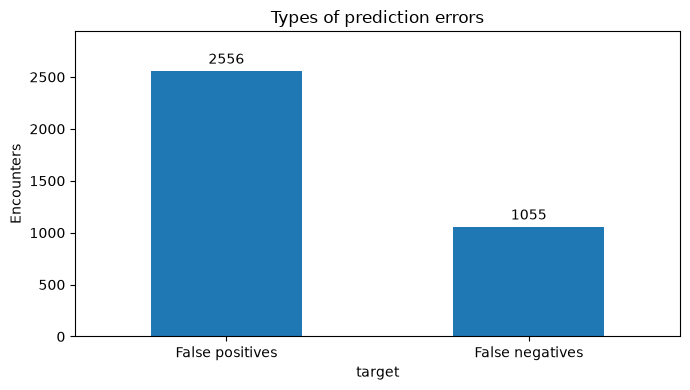

In [58]:
import pandas as pd
import matplotlib.pyplot as plt

audit = Xv.copy()

audit["result"] = "TN"
audit.loc[audit["target"].eq(0) & audit["y_pred"].eq(1), "result"] = "FP"
audit.loc[audit["target"].eq(1) & audit["y_pred"].eq(0), "result"] = "FN"
audit.loc[audit["target"].eq(1) & audit["y_pred"].eq(1), "result"] = "TP"

error_counts = (Errors["target"].map({0: "False positives", 1: "False negatives"}).value_counts().reindex(["False positives", "False negatives"], fill_value=0))

ax = error_counts.plot.bar(figsize=(7, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_ylabel("Encounters")
ax.set_title("Types of prediction errors")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

number_inpatient        number_emergency        time_in_hospital  \
                   mean median             mean median             mean   
result                                                                    
FP                 1.93    2.0             0.44    0.0             5.24   
TP                 2.30    2.0             0.62    0.0             5.25   

              num_medications         
       median            mean median  
result                                
FP        5.0           17.91   17.0  
TP        5.0           18.60   17.0

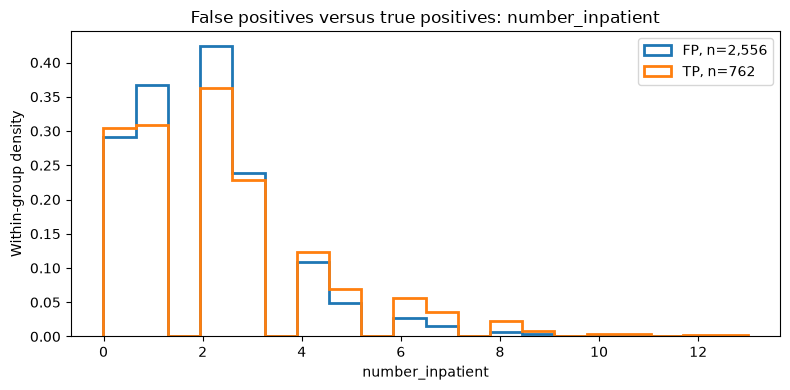

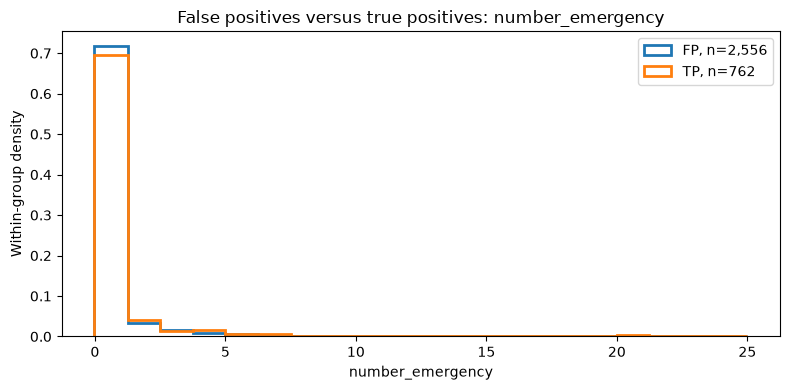

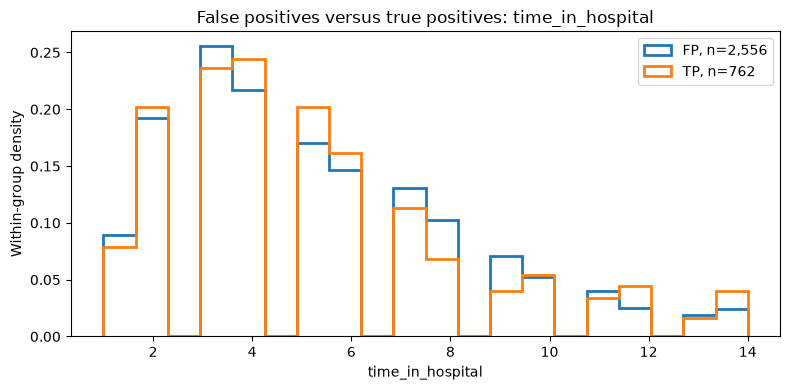

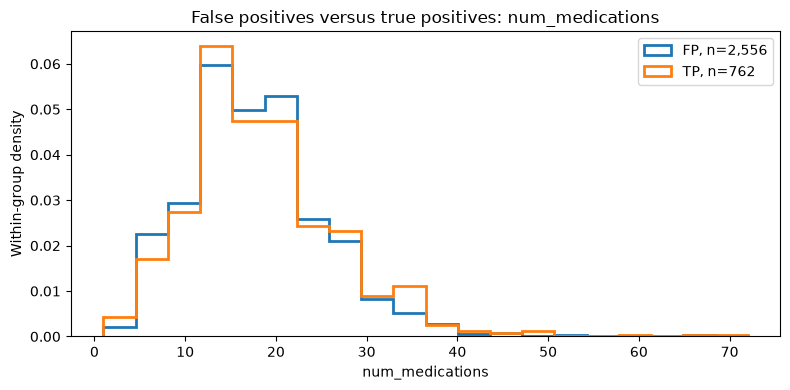

In [59]:
flagged = audit.loc[audit["y_pred"].eq(1)].copy()

columns = ["number_inpatient", "number_emergency", "time_in_hospital", "num_medications",]

display(flagged.groupby("result")[columns].agg(["mean", "median"]).round(2))

for column in columns:
    values = pd.to_numeric(flagged[column], errors="coerce")

    # use identical bin edges for both groups.
    edges = pd.cut(values.dropna(), bins=20, retbins=True)[1]

    plt.figure(figsize=(8, 4))

    for result in ["FP", "TP"]:
        group = values.loc[flagged["result"].eq(result)].dropna()
        plt.hist(group, bins=edges, density=True, histtype="step", linewidth=2, label=f"{result}, n={len(group):,}")

    plt.xlabel(column)
    plt.ylabel("Within-group density")
    plt.title(f"False positives versus true positives: {column}")
    plt.legend()
    plt.tight_layout()
    plt.show()

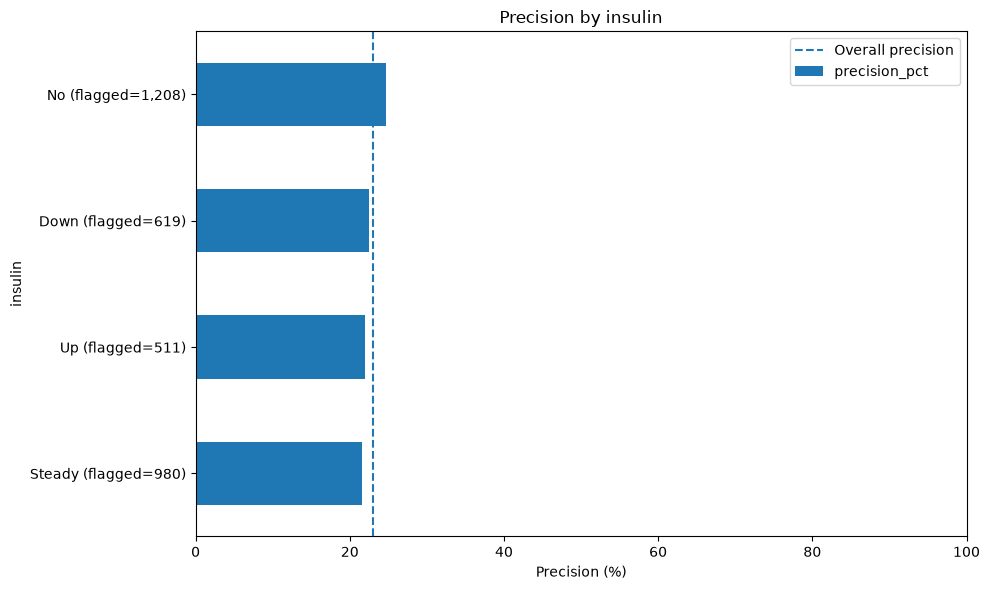

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
insulin,,,,,,,,
No,5811,909,479,299,1208,24.75,13.53,61.57
Steady,3648,768,314,212,980,21.63,17.39,59.70
Down,1265,480,144,139,619,22.46,27.51,50.88
Up,1186,399,118,112,511,21.92,25.17,51.30


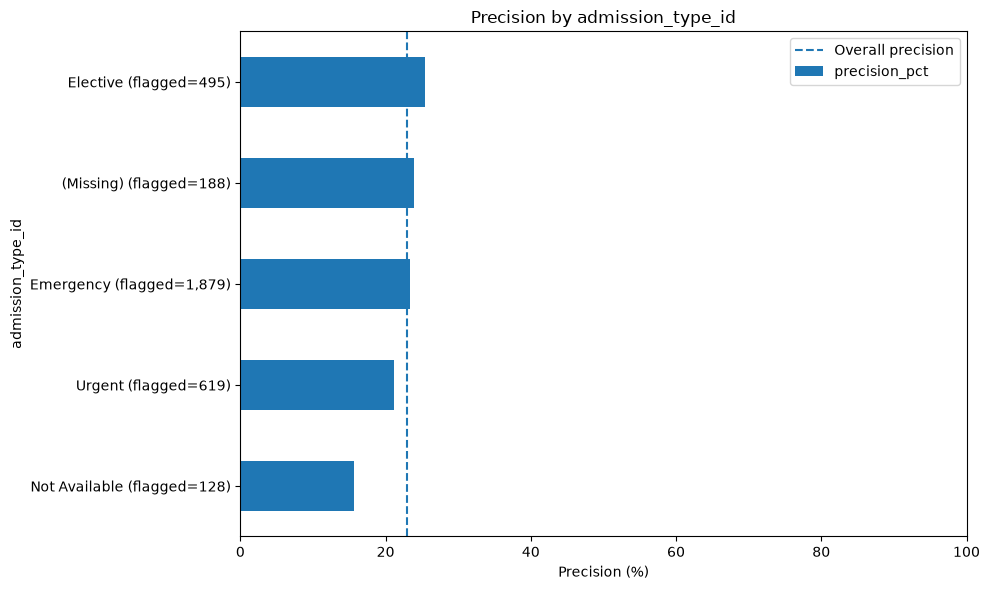

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
admission_type_id,,,,,,,,
Emergency,6187,1441,574,438,1879,23.31,18.89,56.72
Urgent,2113,488,186,131,619,21.16,18.76,58.68
Elective,2402,369,186,126,495,25.45,13.32,59.62
(Missing),594,143,46,45,188,23.94,19.40,50.55
Not Available,555,108,60,20,128,15.62,16.29,75.00
Not Mapped,52,6,3,2,8,25.00,10.34,60.00
Trauma Center,4,1,0,0,1,0.00,20.00,NaN
Newborn,3,0,0,0,0,NaN,0.00,NaN


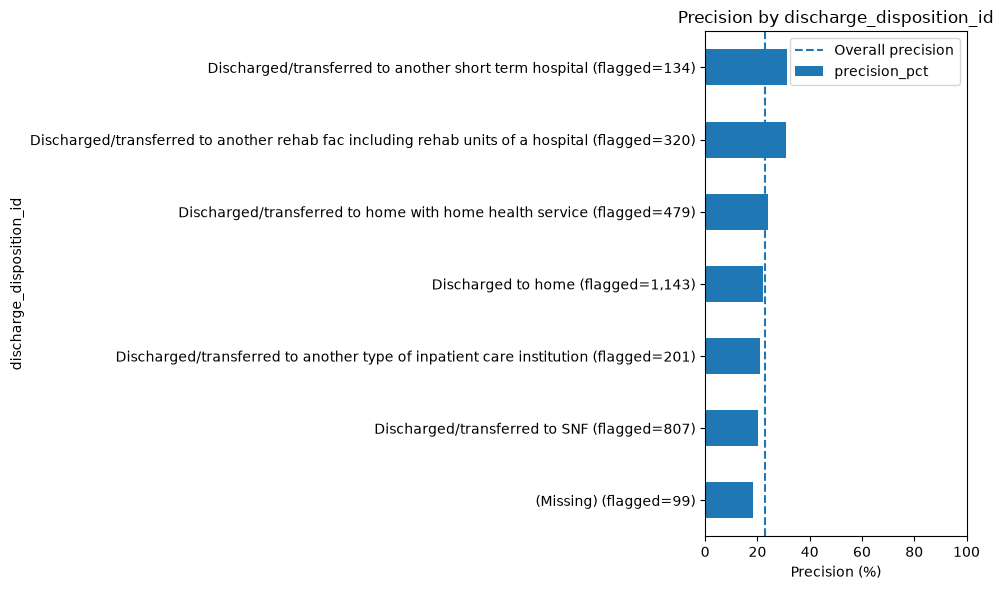

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
discharge_disposition_id,,,,,,,,
Discharged to home,7832,889,649,254,1143,22.22,10.19,71.87
Discharged/transferred to SNF,1250,645,160,162,807,20.07,34.04,49.69
Discharged/transferred to home with home health service,1370,363,131,116,479,24.22,20.95,53.04
Discharged/transferred to another rehab fac including rehab units of a hospital,11,221,2,99,320,30.94,95.26,1.98
Discharged/transferred to another type of inpatient care institution,26,159,2,42,201,20.90,85.95,4.55
Discharged/transferred to another short term hospital,215,92,12,42,134,31.34,29.97,22.22
(Missing),442,81,53,18,99,18.18,15.49,74.65
Discharged/transferred to ICF,99,20,11,7,27,25.93,16.81,61.11
Discharged/transferred to home under care of Home IV provider,3,16,0,0,16,0.00,84.21,NaN


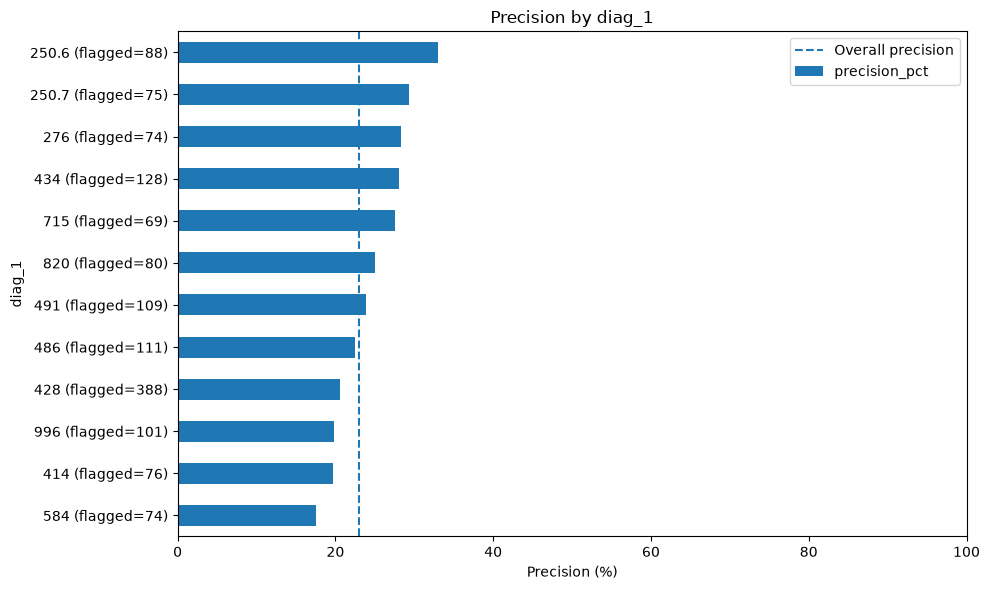

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
diag_1,,,,,,,,
428,626,308,76,80,388,20.62,32.98,48.72
434,179,92,22,36,128,28.12,33.95,37.93
486,441,86,20,25,111,22.52,16.32,44.44
491,242,83,33,26,109,23.85,25.54,55.93
996,177,81,23,20,101,19.80,31.40,53.49
414,900,61,81,15,76,19.74,6.35,84.38
584,172,61,15,13,74,17.57,26.18,53.57
820,77,60,8,20,80,25.00,43.80,28.57
250.6,96,59,19,29,88,32.95,38.06,39.58


In [60]:
# We perform error analysis on based on grouping of insulin, admission types, discharge dispositions, and the actual diagnoses

group_tables = {}
overall_precision = 100 * flagged["target"].mean()

for column in ["insulin", "admission_type_id", "discharge_disposition_id","diag_1"]:
    groups = audit[column].astype("string").fillna("(Missing)")

    table = pd.crosstab(groups, audit["result"]).reindex(columns=["TN", "FP", "FN", "TP"], fill_value=0)

    table["flagged"] = table["TP"] + table["FP"]
    negatives = table["TN"] + table["FP"]
    positives = table["TP"] + table["FN"]

    table["precision_pct"] = 100 * table["TP"] / table["flagged"].where(table["flagged"] > 0)
    

    table["FPR_pct"] = 100 * table["FP"] / negatives.where(negatives > 0)

    table["FNR_pct"] = 100 * table["FN"] / positives.where(positives > 0)

    group_tables[column] = table

    # Show common groups with at least 50 positive predictions.
    shown = table.loc[table["flagged"] >= 50].nlargest(12, "flagged").sort_values("precision_pct")

    ax = shown["precision_pct"].plot.barh(figsize=(10, 6))

    ax.set_yticks(range(len(shown)),[f"{group} (flagged={int(n):,})" for group, n in shown["flagged"].items()])

    ax.axvline(overall_precision, linestyle="--", label="Overall precision")

    ax.set_xlim(0, 100)
    ax.set_xlabel("Precision (%)")
    ax.set_title(f"Precision by {column}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Rank by the actual number of false positives.
    display(table.sort_values("FP", ascending=False).head(12).round(2))

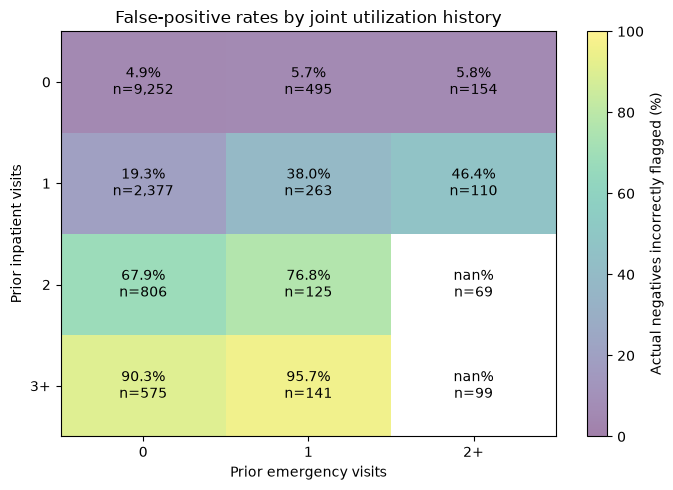

actual_negatives  false_positives    FPR
inpatient_band emergency_band                                          
0              0                           9252              457  0.049
               1                            495               28  0.057
               2+                           154                9  0.058
1              0                           2377              458  0.193
               1                            263              100  0.380
               2+                           110               51  0.464
2              0                            806              547  0.679
               1                            125               96  0.768
               2+                            69               62  0.899
3+             0                            575              519  0.903
               1                            141              135  0.957
               2+                            99               94  0.949

In [61]:
audit["inpatient_band"] = pd.cut(pd.to_numeric(audit["number_inpatient"], errors="coerce"), bins=[-float("inf"), 0, 1, 2, float("inf")], labels=["0", "1", "2", "3+"])

audit["emergency_band"] = pd.cut(pd.to_numeric(audit["number_emergency"], errors="coerce"), bins=[-float("inf"), 0, 1, float("inf")], labels=["0", "1", "2+"])

negative = audit.loc[audit["target"].eq(0)]

joint = negative.groupby(["inpatient_band", "emergency_band"], observed=True)["y_pred"].agg(actual_negatives="size", false_positives="sum", FPR="mean")

counts = joint["actual_negatives"].unstack().reindex(index=["0", "1", "2", "3+"],columns=["0", "1", "2+"]).fillna(0)

rates = 100 * joint["FPR"].unstack().reindex_like(counts)
shown = rates.where(counts >= 100)

plt.figure(figsize=(7, 5))
plt.imshow(shown.to_numpy(dtype=float), aspect="auto",vmin=0, vmax=100, alpha=0.5)

plt.xticks(range(len(shown.columns)), shown.columns)
plt.yticks(range(len(shown.index)), shown.index)

for i in range(len(shown.index)):
    for j in range(len(shown.columns)):
        plt.text(j, i, f"{shown.iloc[i, j]:.1f}%\nn={int(counts.iloc[i, j]):,}", ha="center", va="center")

plt.xlabel("Prior emergency visits")
plt.ylabel("Prior inpatient visits")
plt.title("False-positive rates by joint utilization history")
plt.colorbar(label="Actual negatives incorrectly flagged (%)")
plt.tight_layout()
plt.show()

display(joint.round(3))

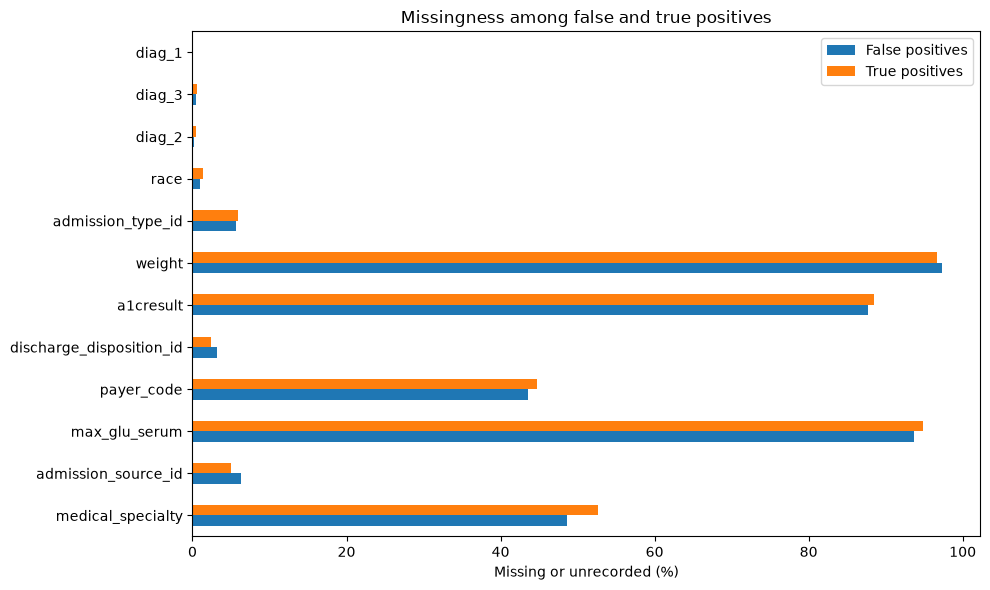

,False positives,True positives,difference_percentage_points
medical_specialty,48.67,52.62,-3.95
admission_source_id,6.30,4.99,1.31
max_glu_serum,93.66,94.88,-1.22
payer_code,43.58,44.75,-1.17
discharge_disposition_id,3.17,2.36,0.81
a1cresult,87.68,88.45,-0.78
weight,97.38,96.72,0.66
admission_type_id,5.59,5.91,-0.31
race,1.02,1.31,-0.30
diag_2,0.16,0.39,-0.24


In [62]:
columns = [column for column in flagged.columns if column not in ["target", "y_pred", "result", "patient_nbr", "encounter_id"]]

missing = flagged[columns].isna() | flagged[columns].astype("string").isin(["?", "", "missing"])

missing_rates = 100 * pd.DataFrame({"False positives": missing.loc[flagged["result"].eq("FP")].mean(),
                                    "True positives": missing.loc[flagged["result"].eq("TP")].mean()})

missing_rates = missing_rates.loc[missing_rates.gt(0).any(axis=1)]

difference = missing_rates["False positives"] - missing_rates["True positives"]

order = difference.abs().nlargest(12).index

if len(order):
    missing_rates.loc[order].plot.barh(figsize=(10, 6))
    plt.xlabel("Missing or unrecorded (%)")
    plt.ylabel("")
    plt.title("Missingness among false and true positives")
    plt.tight_layout()
    plt.show()

    display(missing_rates.assign(difference_percentage_points=difference).loc[order].round(2))